In [146]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import random

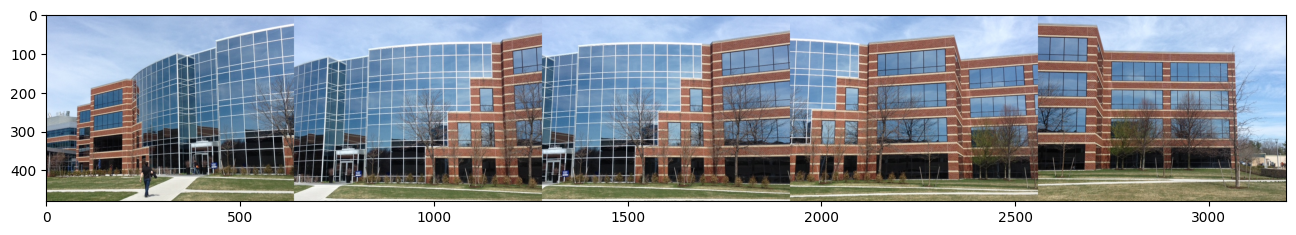

In [167]:
path_folder = Path("building1")

imgs = [cv.imread(img) for img in sorted(path_folder.glob("*.jpg"))]
combined = np.concatenate(imgs, axis=1)

plt.figure(figsize=(16, 5))
plt.imshow(cv.cvtColor(combined, cv.COLOR_BGR2RGB))
plt.show()


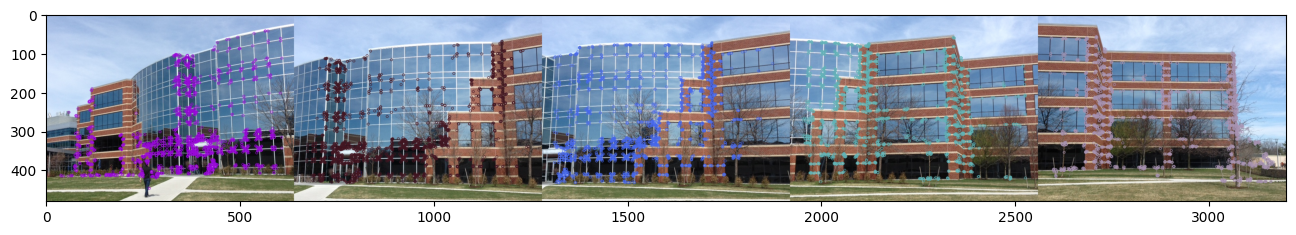

In [162]:
orb = cv.ORB_create(nfeatures=2000)

keypoints_discriptors = [orb.detectAndCompute(cv.imread(img), None) for img in sorted(path_folder.glob("*.jpg"))]

imgs_with_points = [
    cv.drawKeypoints(imgs[i], keypoints_discriptors[i][0], None, (
        random.randint(0, 255), 
        random.randint(0, 255), 
        random.randint(0, 255)
        )) 
        for i in range(len(imgs))]

combined = np.concatenate(imgs_with_points, axis=1)

plt.figure(figsize=(16, 5))
plt.imshow(cv.cvtColor(combined, cv.COLOR_BGR2RGB))
plt.show()


In [163]:
def draw_matches(img1, keypoints1, img2, keypoints2, matches):
    return cv.drawMatches(
        img1, keypoints1,
        img2, keypoints2,
        matches, None,
        matchColor=(0, 255, 255),
        flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

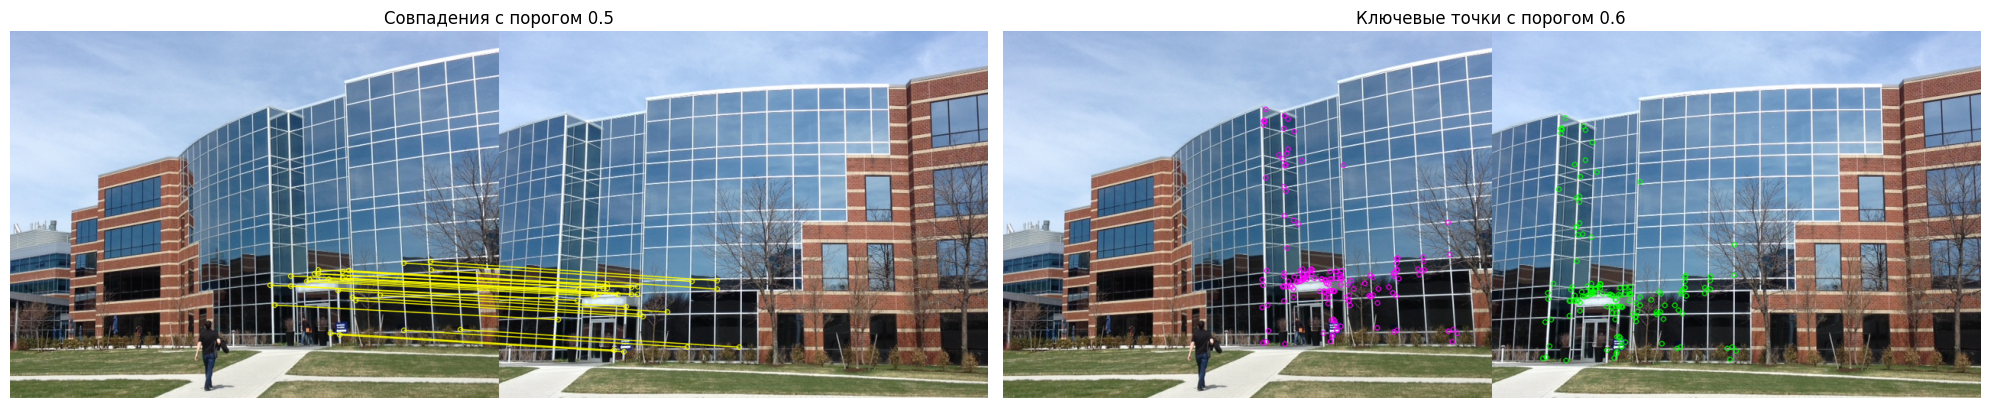

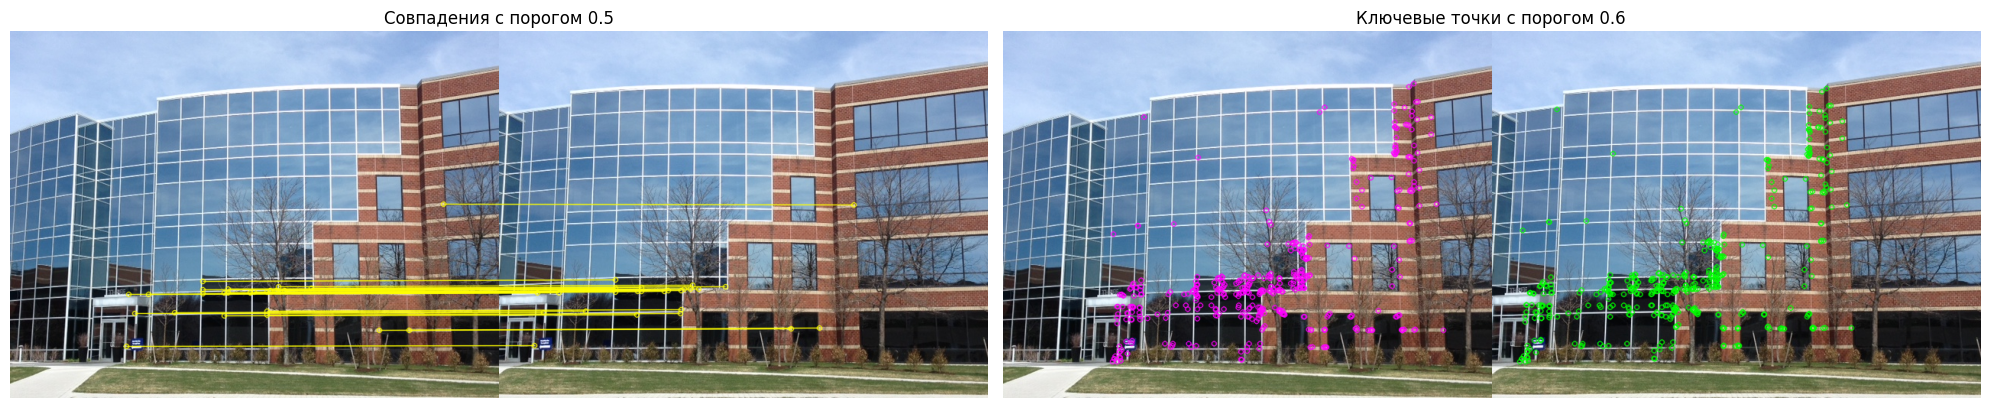

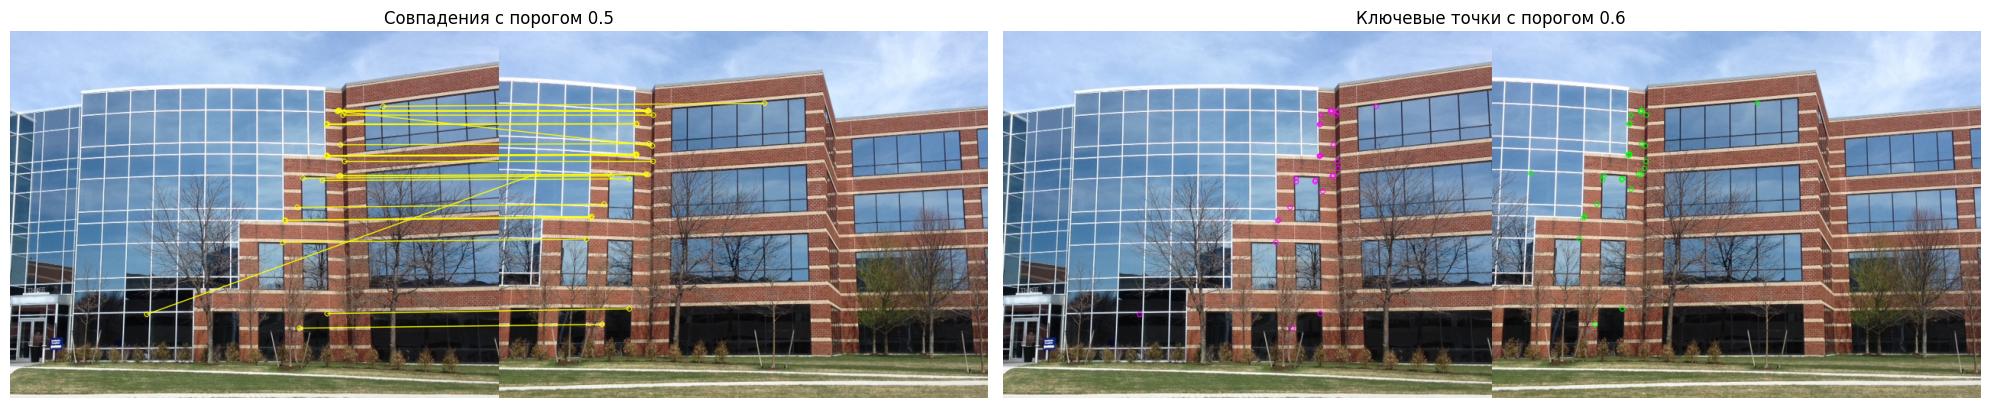

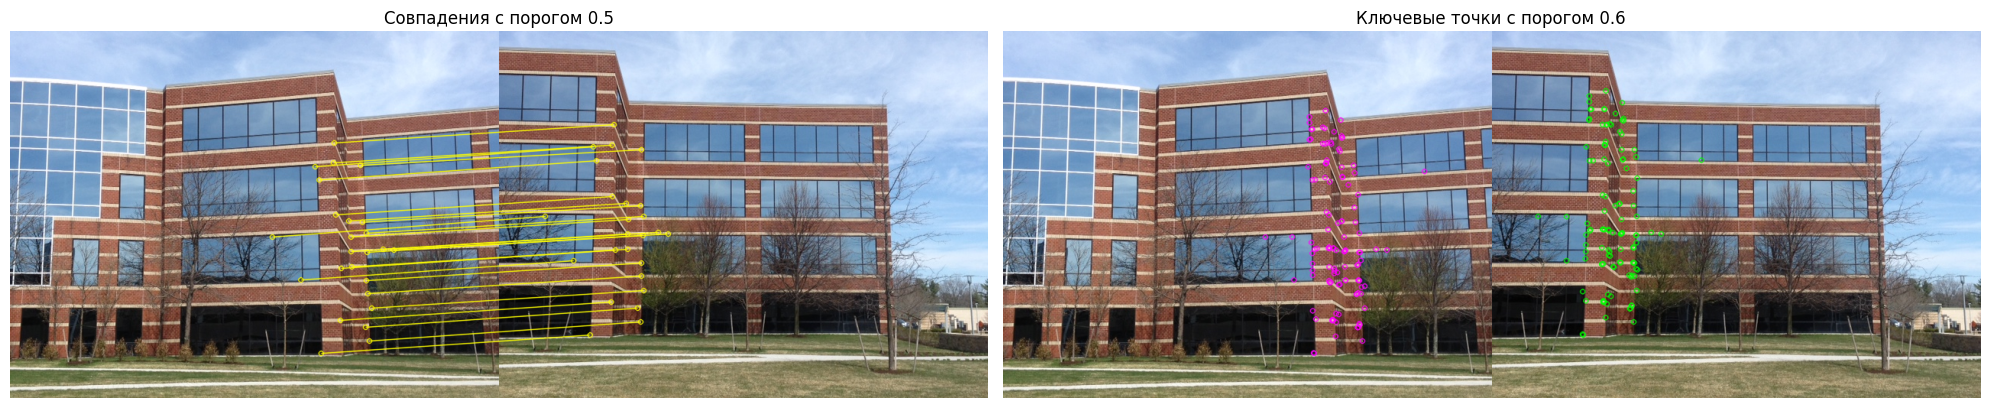

In [164]:
bf = cv.BFMatcher_create(cv.NORM_HAMMING)

for i in range(len(keypoints_discriptors) - 1):
    keypoints1, descriptors1 = keypoints_discriptors[i]
    keypoints2, descriptors2 = keypoints_discriptors[i + 1]

    matches = bf.knnMatch(descriptors1, descriptors2, k=2)

    good_matches = []  
    good = []          

    for pair in matches:
        if len(pair) == 2:
            m, n = pair
            if m.distance < 0.5 * n.distance:
                good_matches.append(m)
            if m.distance < 0.5 * n.distance:
                good.append(m)

    img_matches = draw_matches(
        imgs[i], keypoints1,
        imgs[i + 1], keypoints2,
        good_matches[:25]
    )

    img1_kp = cv.drawKeypoints(
        imgs[i],
        [keypoints1[m.queryIdx] for m in good],
        None,
        (255, 0, 255)
    )
    img2_kp = cv.drawKeypoints(
        imgs[i + 1],
        [keypoints2[m.trainIdx] for m in good],
        None,
        (0, 255, 0)
    )
    img_keypoints = np.concatenate((img1_kp, img2_kp), axis=1)

    fig, axes = plt.subplots(1, 2, figsize=(20, 6))
    axes[0].imshow(cv.cvtColor(img_matches, cv.COLOR_BGR2RGB))
    axes[0].set_title("Совпадения с порогом 0.5")
    axes[0].axis("off")

    axes[1].imshow(cv.cvtColor(img_keypoints, cv.COLOR_BGR2RGB))
    axes[1].set_title("Ключевые точки с порогом 0.6")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

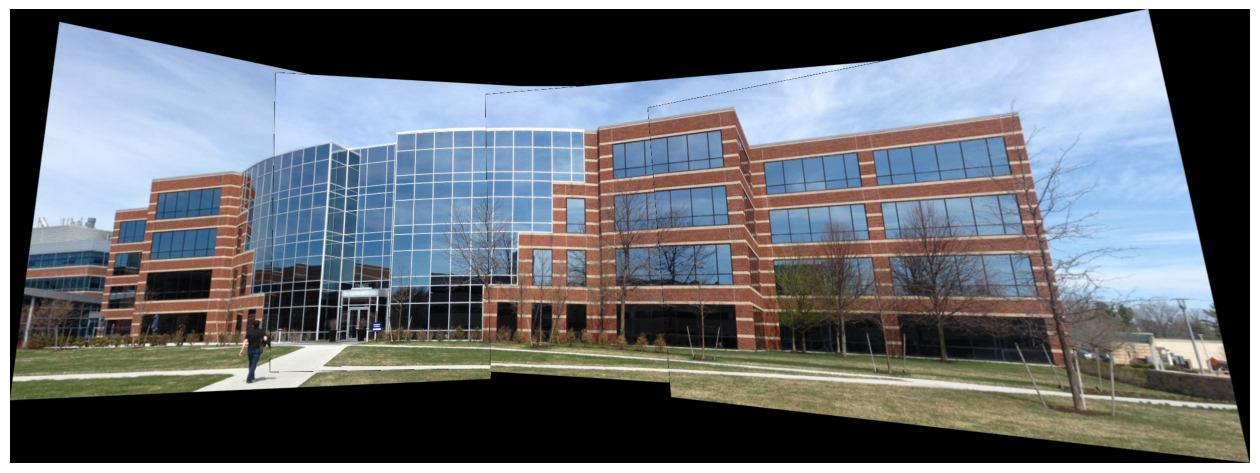

Сохранено: /Users/asya/Documents/cv_hw/hw4/results/building1_panorama.jpg


In [ ]:
def estimate_pair_homography(img1, img2, orb, matcher, ratio=0.6):
    keypoints1, descriptors1 = orb.detectAndCompute(img1, None)
    keypoints2, descriptors2 = orb.detectAndCompute(img2, None)
    matches = matcher.knnMatch(descriptors1, descriptors2, k=2)

    good = []
    for pair in matches:
        if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance:
            good.append(pair[0])

    src_pts = np.float32(
        [keypoints1[m.queryIdx].pt for m in good]
    ).reshape(-1, 1, 2)
    dst_pts = np.float32(
        [keypoints2[m.trainIdx].pt for m in good]
    ).reshape(-1, 1, 2)

    H, _ = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)
    
    rows, cols = img1.shape[:2]
    corners = np.float32([
        [0, 0], [cols, 0], [cols, rows], [0, rows]
    ]).reshape(-1, 1, 2)
    transformed_corners = cv.perspectiveTransform(corners, H)
    area_ratio = abs(cv.contourArea(transformed_corners)) / (rows * cols)

    if area_ratio < 0.5 or area_ratio > 2.0:
        A, _ = cv.estimateAffine2D(
            src_pts.reshape(-1, 2),
            dst_pts.reshape(-1, 2),
            method=cv.RANSAC,
            ransacReprojThreshold=5.0
        )
        if A is not None:
            H = np.vstack([A, [0, 0, 1]])

    return H


def build_panorama(images, orb, matcher, ratio=0.6):
    middle = len(images) // 2
    transforms = [None] * len(images)
    transforms[middle] = np.eye(3)

    for i in range(middle + 1, len(images)):
        H = estimate_pair_homography(images[i], images[i - 1], orb, matcher, ratio)
        transforms[i] = transforms[i - 1] @ H

    for i in range(middle - 1, -1, -1):
        H = estimate_pair_homography(images[i + 1], images[i], orb, matcher, ratio)
        transforms[i] = transforms[i + 1] @ np.linalg.inv(H)

    corners = []
    for img, H in zip(images, transforms):
        h, w = img.shape[:2]
        points = np.float32([[0, 0], [0, h], [w, h], [w, 0]]).reshape(-1, 1, 2)
        corners.append(cv.perspectiveTransform(points, H))

    corners = np.concatenate(corners, axis=0)
    x_min, y_min = np.int32(corners.min(axis=0).ravel() - 0.5)
    x_max, y_max = np.int32(corners.max(axis=0).ravel() + 0.5)

    shift = np.array([
        [1, 0, -x_min],
        [0, 1, -y_min],
        [0, 0, 1]
    ])
    size = (x_max - x_min, y_max - y_min)
    panorama = np.zeros((size[1], size[0], 3), dtype=np.uint8)

    for i, img in enumerate(images):
        H = shift @ transforms[i]
        warped = cv.warpPerspective(img, H, size)
        mask = np.any(warped != 0, axis=2)
        panorama[mask] = warped[mask]

    return panorama


def stitch_folder(folder_path, results_dir, ratio=0.6):
    folder_path = Path(folder_path)
    results_dir = Path(results_dir)
    image_paths = sorted(folder_path.glob("*.jpg"))
    images = [cv.imread(str(image_path)) for image_path in image_paths]

    orb = cv.ORB_create(nfeatures=2000)
    matcher = cv.BFMatcher_create(cv.NORM_HAMMING)
    panorama = build_panorama(images, orb, matcher, ratio)

    results_dir.mkdir(parents=True, exist_ok=True)
    output_path = results_dir / f"{folder_path.name}_panorama.jpg"
    cv.imwrite(str(output_path), panorama)

    plt.figure(figsize=(16, 8))
    plt.imshow(cv.cvtColor(panorama, cv.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()
    print(f"Сохранено: {output_path}")

    return panorama, output_path


results_dir = path_folder.parent / "results"
panorama, output_path = stitch_folder(path_folder, results_dir)
